In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')
path = kagglehub.dataset_download("habibaishfaq/diabetes-prediction")
print("Path to dataset files:", path)

/kaggle/input/datasets/habibaishfaq/diabetes-prediction/diabetes_prediction_dataset.csv
Path to dataset files: /kaggle/input/datasets/habibaishfaq/diabetes-prediction


In [2]:
df = pd.read_csv("/kaggle/input/datasets/habibaishfaq/diabetes-prediction/diabetes_prediction_dataset.csv")
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [3]:
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB
None
                 age  hypertension  heart_disease            bmi  \
count  100000.000000  100000.00000  100000.000000  100000.000000   
mean       41.885856       0.07485       0.039420      27.320767   
std        22.516840       0.26315       0.194593       6.6

In [4]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [5]:
old_len = len(df)

df = df.drop_duplicates().copy()

new_len = len(df)

print("Removed:", old_len - new_len, "duplicate rows")
print("Updated Shape:", df.shape)

Removed: 3854 duplicate rows
Updated Shape: (96146, 9)


In [6]:
print(df['diabetes'].value_counts())

print("\nPercentage Distribution:")
print(df['diabetes'].value_counts(normalize=True) * 100)

diabetes
0    87664
1     8482
Name: count, dtype: int64

Percentage Distribution:
diabetes
0    91.178
1     8.822
Name: proportion, dtype: float64


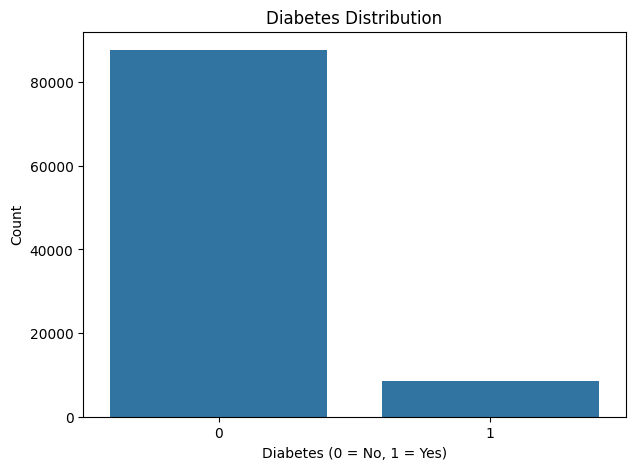

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='diabetes')

plt.title("Diabetes Distribution")
plt.xlabel("Diabetes (0 = No, 1 = Yes)")
plt.ylabel("Count")

plt.show()

In [8]:
categorical_cols = ['gender', 'smoking_history']

for col in categorical_cols:
    print(f"\n{col} Distribution:")
    print(df[col].value_counts())


gender Distribution:
gender
Female    56161
Male      39967
Other        18
Name: count, dtype: int64

smoking_history Distribution:
smoking_history
never          34398
No Info        32887
former          9299
current         9197
not current     6367
ever            3998
Name: count, dtype: int64


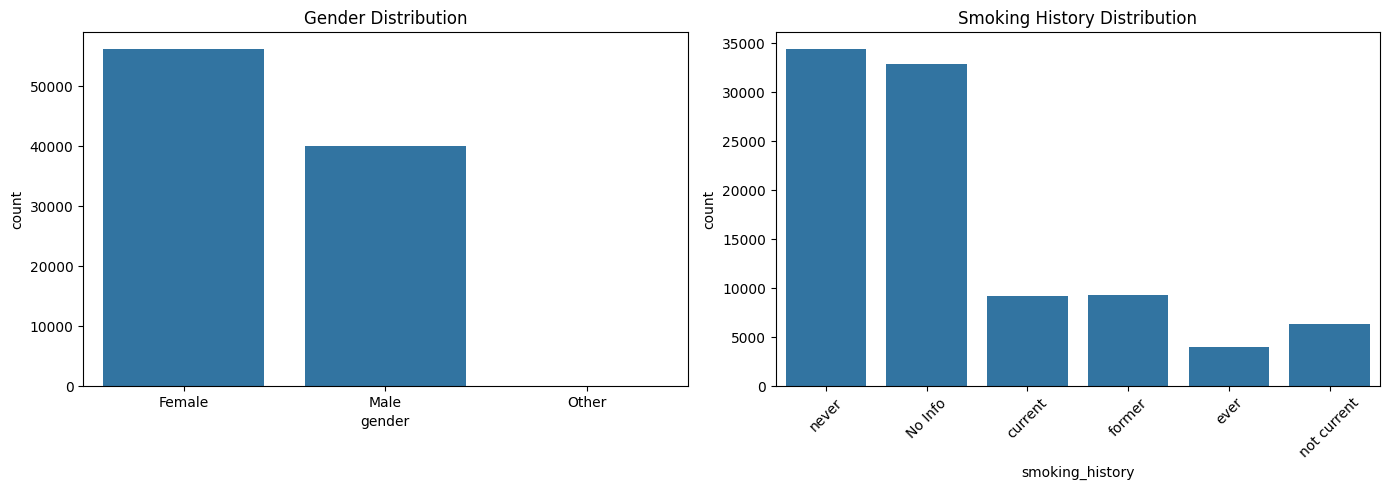

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x='gender', ax=axes[0])
axes[0].set_title("Gender Distribution")

sns.countplot(data=df, x='smoking_history', ax=axes[1])
axes[1].set_title("Smoking History Distribution")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

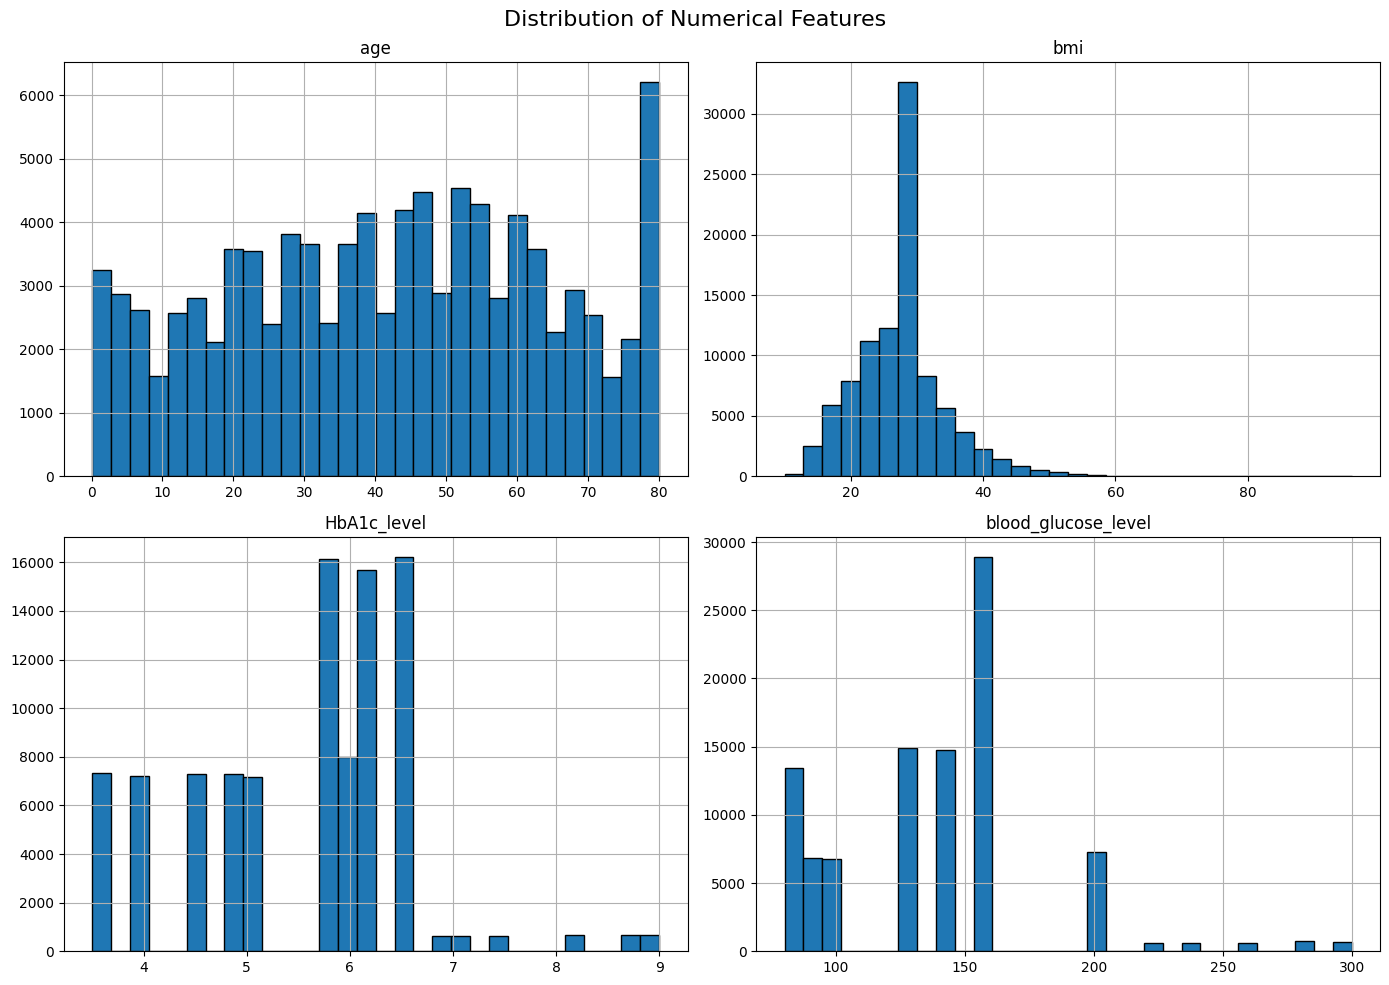

In [10]:
numerical_cols = [
    'age',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level'
]

df[numerical_cols].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor='black'
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

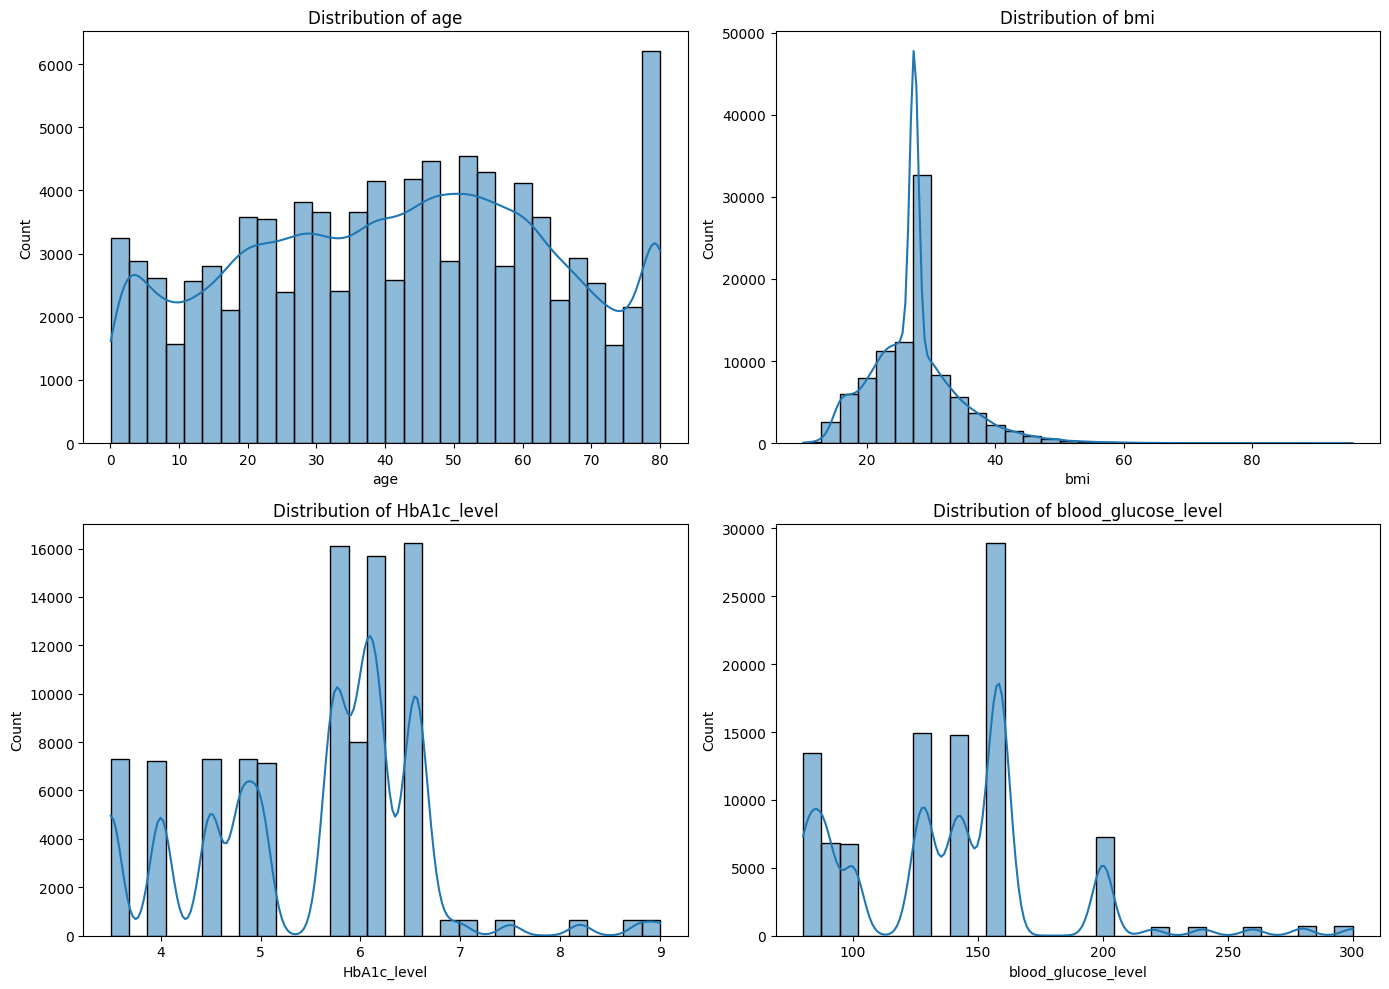

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for col, ax in zip(numerical_cols, axes.flatten()):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30,
        ax=ax
    )
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

In [12]:
print(df[numerical_cols].describe().T)

                       count        mean        std    min    25%     50%  \
age                  96146.0   41.794326  22.462948   0.08   24.0   43.00   
bmi                  96146.0   27.321461   6.767716  10.01   23.4   27.32   
HbA1c_level          96146.0    5.532609   1.073232   3.50    4.8    5.80   
blood_glucose_level  96146.0  138.218231  40.909771  80.00  100.0  140.00   

                        75%     max  
age                   59.00   80.00  
bmi                   29.86   95.69  
HbA1c_level            6.20    9.00  
blood_glucose_level  159.00  300.00  


In [13]:
skewness = df[numerical_cols].skew()

print("Skewness of Numerical Features:")
print(skewness.sort_values(ascending=False))

Skewness of Numerical Features:
bmi                    1.023751
blood_glucose_level    0.836489
HbA1c_level           -0.054463
age                   -0.062445
dtype: float64


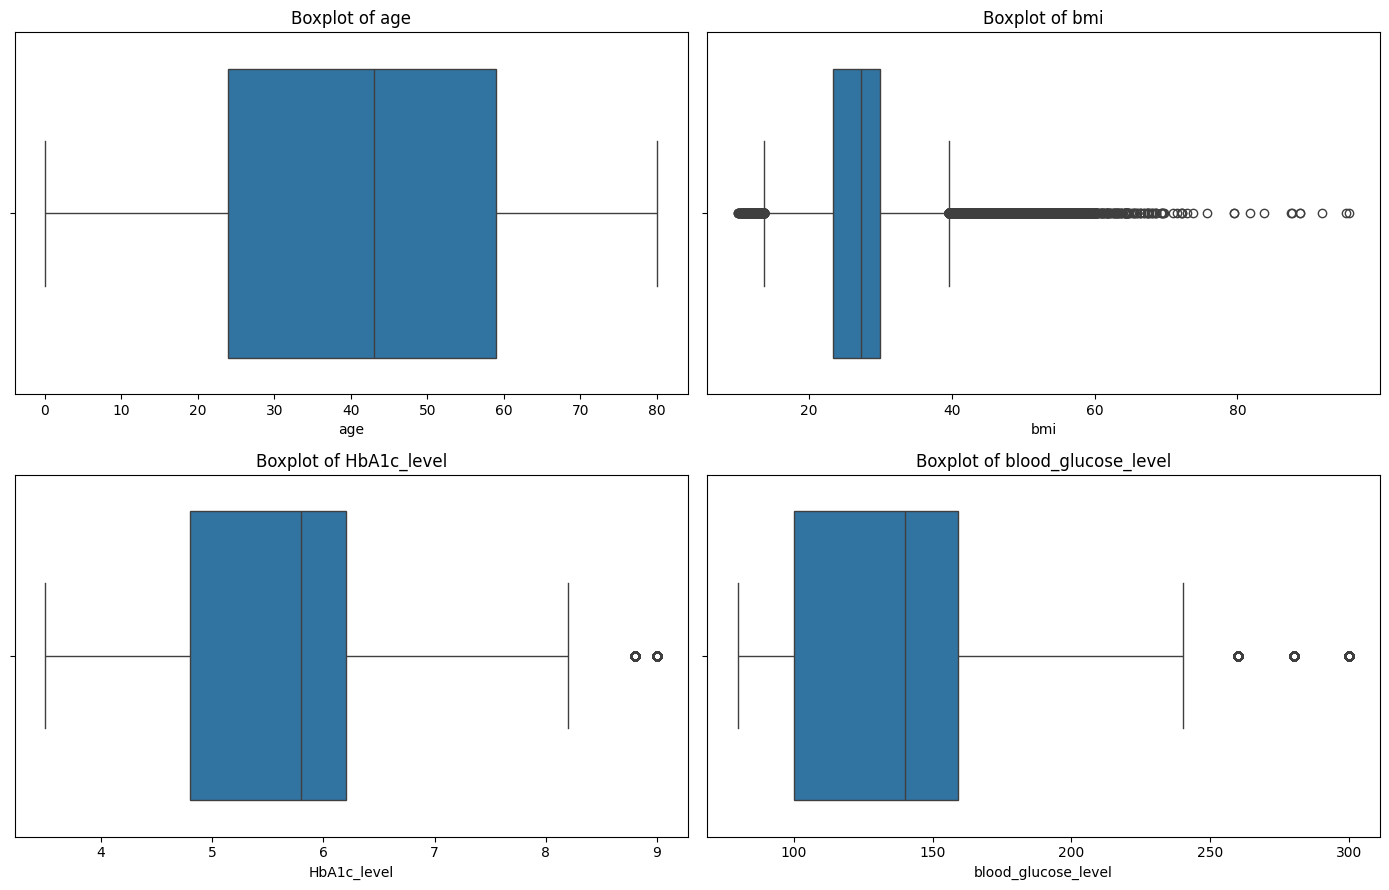

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for col, ax in zip(numerical_cols, axes.flatten()):
    sns.boxplot(data=df, x=col, ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

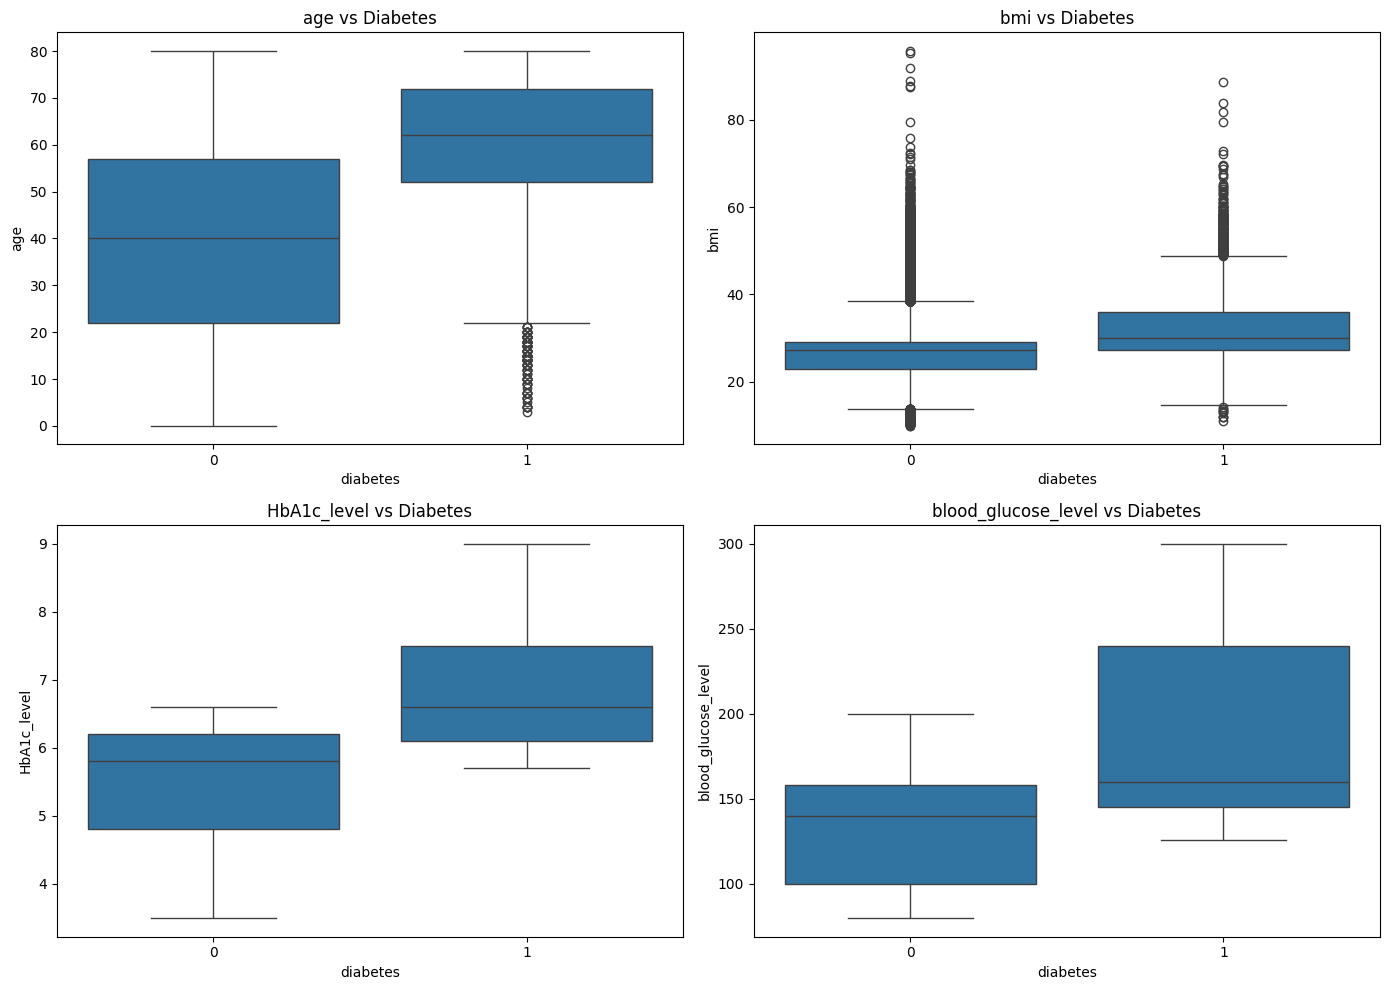

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for col, ax in zip(numerical_cols, axes.flatten()):
    sns.boxplot(
        data=df,
        x='diabetes',
        y=col,
        ax=ax
    )
    ax.set_title(f'{col} vs Diabetes')

plt.tight_layout()
plt.show()

In [16]:
categorical_cols = ['gender', 'smoking_history']

for col in categorical_cols:

    print(f"\nDiabetes Rate by {col}:")

    result = df.groupby(col)['diabetes'].agg(
        ['count', 'sum', 'mean']
    )

    result['diabetes_percentage'] = result['mean'] * 100

    print(result.round(2))


Diabetes Rate by gender:
        count   sum  mean  diabetes_percentage
gender                                        
Female  56161  4447  0.08                 7.92
Male    39967  4035  0.10                10.10
Other      18     0  0.00                 0.00

Diabetes Rate by smoking_history:
                 count   sum  mean  diabetes_percentage
smoking_history                                        
No Info          32887  1445  0.04                 4.39
current           9197   948  0.10                10.31
ever              3998   472  0.12                11.81
former            9299  1590  0.17                17.10
never            34398  3337  0.10                 9.70
not current       6367   690  0.11                10.84


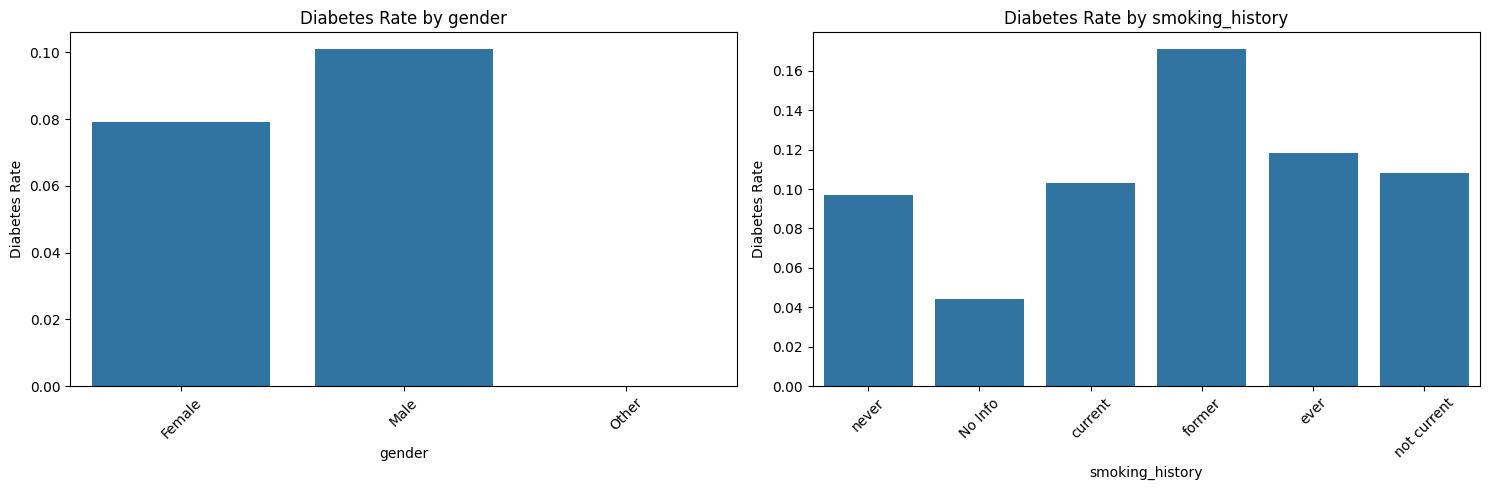

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for col, ax in zip(categorical_cols, axes):

    sns.barplot(
        data=df,
        x=col,
        y='diabetes',
        errorbar=None,
        ax=ax
    )

    ax.set_title(f'Diabetes Rate by {col}')
    ax.set_ylabel('Diabetes Rate')
    ax.set_xlabel(col)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

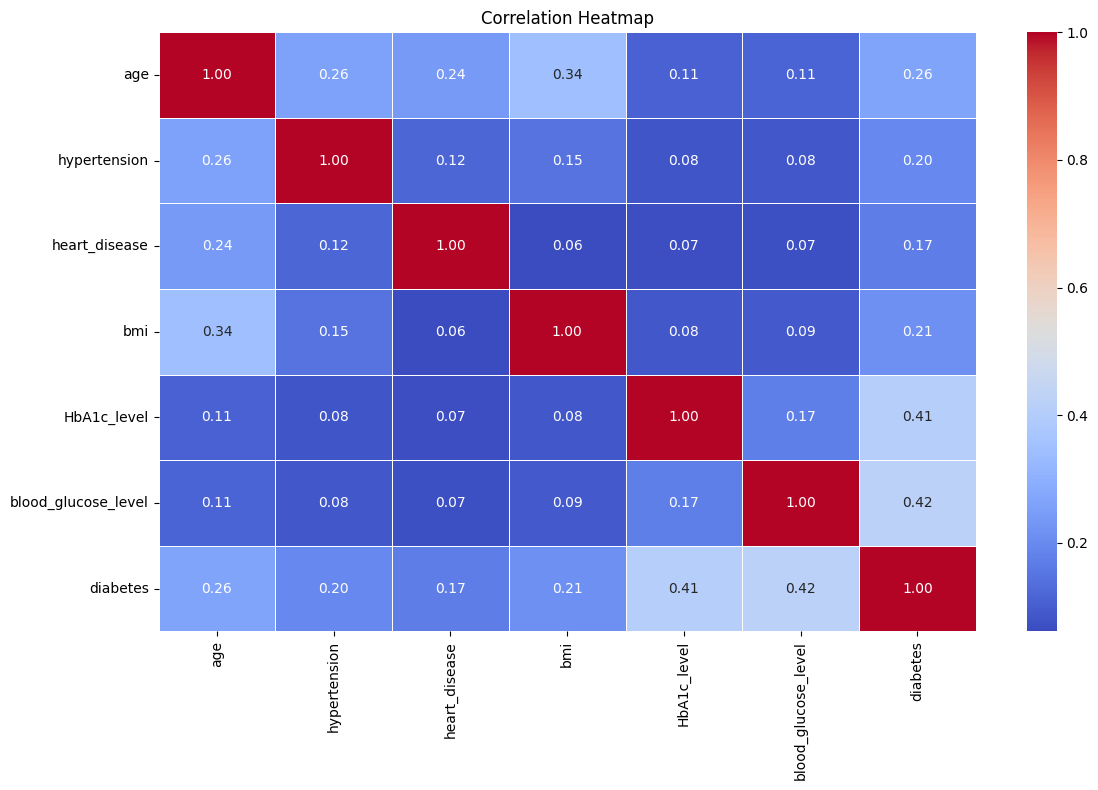

In [18]:
plt.figure(figsize=(12, 8))

corr = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [19]:
target_corr = corr['diabetes'].drop('diabetes')

target_corr = target_corr.sort_values(
    ascending=False
)

print("Correlation with Diabetes:")
print(target_corr)

Correlation with Diabetes:
blood_glucose_level    0.424336
HbA1c_level            0.406408
age                    0.264927
bmi                    0.214932
hypertension           0.195710
heart_disease          0.170711
Name: diabetes, dtype: float64


Done with EDA and understanding of the data

In [20]:
X = df.drop(columns=['diabetes'])
y = df['diabetes']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts(normalize=True) * 100)

Feature Shape: (96146, 8)
Target Shape: (96146,)

Target Distribution:
diabetes
0    91.178
1     8.822
Name: proportion, dtype: float64


In [21]:
numerical_cols = [
    'age',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level',
    'hypertension',
    'heart_disease'
]

categorical_cols = [
    'gender',
    'smoking_history'
]

print("Numerical Features:", numerical_cols)
print("Categorical Features:", categorical_cols)

Numerical Features: ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'hypertension', 'heart_disease']
Categorical Features: ['gender', 'smoking_history']


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Features: (76916, 8)
Testing Features: (19230, 8)

Training Target Distribution:
diabetes
0    91.177388
1     8.822612
Name: proportion, dtype: float64

Testing Target Distribution:
diabetes
0    91.180447
1     8.819553
Name: proportion, dtype: float64


In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),

        ('cat', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ), categorical_cols)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [24]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

In [25]:
models = {
    'Dummy Classifier': DummyClassifier(
        strategy='most_frequent'
    ),

    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    ),

    'Hist Gradient Boosting': HistGradientBoostingClassifier(
        max_iter=100,
        random_state=42
    ),

    'SGD Classifier': SGDClassifier(
        loss='log_loss',
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    )
}

print("Total algorithms:", len(models))

Total algorithms: 8


In [26]:
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    print(f"Training {name}...")

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

print("\nAll models trained successfully!")

Training Dummy Classifier...
Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training Extra Trees...
Training Gradient Boosting...
Training Hist Gradient Boosting...
Training SGD Classifier...

All models trained successfully!


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC AUC': roc_auc_score(y_test, y_prob),
        'PR AUC': average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)

print(results_df.round(4))

                    Model  Accuracy  Precision  Recall  F1 Score  ROC AUC  \
0  Hist Gradient Boosting    0.9716     0.9784  0.6928    0.8112   0.9771   
1       Gradient Boosting    0.9717     0.9873  0.6881    0.8110   0.9774   
2           Random Forest    0.9690     0.9449  0.6881    0.7963   0.9615   
3             Extra Trees    0.9651     0.8995  0.6804    0.7748   0.9510   
4           Decision Tree    0.9513     0.7150  0.7441    0.7293   0.8580   
5     Logistic Regression    0.8845     0.4251  0.8797    0.5732   0.9601   
6          SGD Classifier    0.8761     0.4074  0.8909    0.5591   0.9600   
7        Dummy Classifier    0.9118     0.0000  0.0000    0.0000   0.5000   

   PR AUC  
0  0.8811  
1  0.8841  
2  0.8555  
3  0.8243  
4  0.5591  
5  0.8166  
6  0.8157  
7  0.0882  


In [28]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model Training:", X_fit.shape)
print("Validation:", X_val.shape)

Model Training: (61532, 8)
Validation: (15384, 8)


In [29]:
from sklearn.base import clone

candidate_names = [
    'Hist Gradient Boosting',
    'Gradient Boosting',
    'Random Forest',
    'Logistic Regression'
]

validation_models = {}

for name in candidate_names:

    model = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('classifier', clone(models[name]))
    ])

    print("Training:", name)

    model.fit(X_fit, y_fit)

    validation_models[name] = model

print("\nValidation models trained.")

Training: Hist Gradient Boosting
Training: Gradient Boosting
Training: Random Forest
Training: Logistic Regression

Validation models trained.


In [30]:
import numpy as np

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

threshold_results = []

thresholds = np.arange(0.10, 0.71, 0.05)

for name, model in validation_models.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        threshold_results.append({
            'Model': name,
            'Threshold': round(threshold, 2),

            'Accuracy': accuracy_score(
                y_val, predictions
            ),

            'Precision': precision_score(
                y_val, predictions,
                zero_division=0
            ),

            'Recall': recall_score(
                y_val, predictions,
                zero_division=0
            ),

            'F1 Score': f1_score(
                y_val, predictions,
                zero_division=0
            )
        })

threshold_df = pd.DataFrame(threshold_results)

print(
    threshold_df.round(4).to_string(index=False)
)

                 Model  Threshold  Accuracy  Precision  Recall  F1 Score
Hist Gradient Boosting       0.10    0.9116     0.4994  0.9123    0.6455
Hist Gradient Boosting       0.15    0.9356     0.5931  0.8615    0.7025
Hist Gradient Boosting       0.20    0.9493     0.6754  0.8187    0.7402
Hist Gradient Boosting       0.25    0.9584     0.7526  0.7870    0.7695
Hist Gradient Boosting       0.30    0.9638     0.8231  0.7509    0.7854
Hist Gradient Boosting       0.35    0.9674     0.8815  0.7288    0.7979
Hist Gradient Boosting       0.40    0.9694     0.9284  0.7074    0.8030
Hist Gradient Boosting       0.45    0.9700     0.9479  0.6979    0.8039
Hist Gradient Boosting       0.50    0.9707     0.9660  0.6920    0.8064
Hist Gradient Boosting       0.55    0.9708     0.9799  0.6831    0.8050
Hist Gradient Boosting       0.60    0.9709     0.9924  0.6758    0.8040
Hist Gradient Boosting       0.65    0.9709     0.9978  0.6721    0.8032
Hist Gradient Boosting       0.70    0.9709     1.0

In [31]:
best_thresholds = (
    threshold_df
    .sort_values('F1 Score', ascending=False)
    .groupby('Model')
    .head(1)
    .sort_values('F1 Score', ascending=False)
)

print(best_thresholds.round(4))

                     Model  Threshold  Accuracy  Precision  Recall  F1 Score
19       Gradient Boosting        0.4    0.9702     0.9368  0.7097    0.8075
8   Hist Gradient Boosting        0.5    0.9707     0.9660  0.6920    0.8064
38           Random Forest        0.7    0.9706     0.9967  0.6691    0.8007
51     Logistic Regression        0.7    0.9276     0.5639  0.7900    0.6581


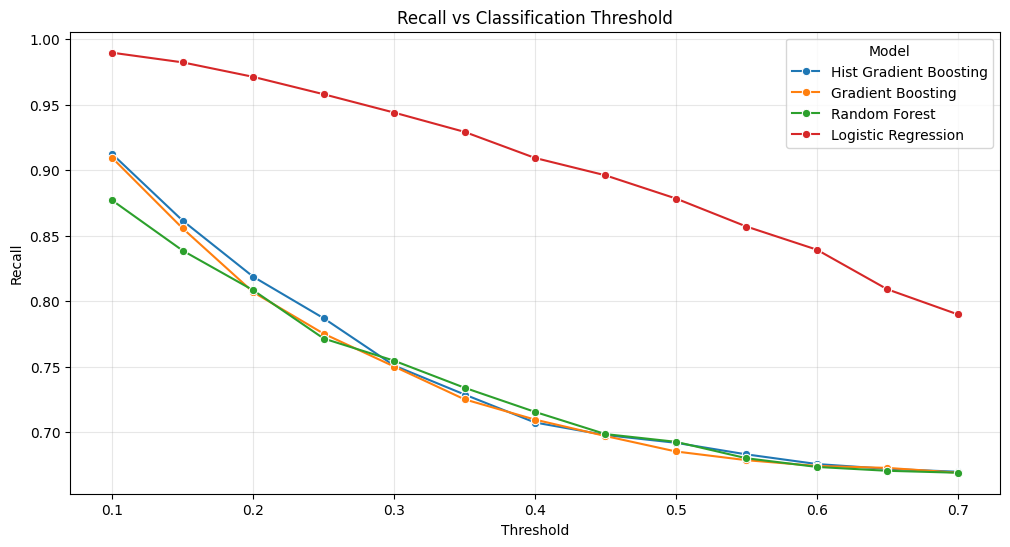

In [32]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=threshold_df,
    x='Threshold',
    y='Recall',
    hue='Model',
    marker='o'
)

plt.title('Recall vs Classification Threshold')
plt.grid(alpha=0.3)
plt.show()

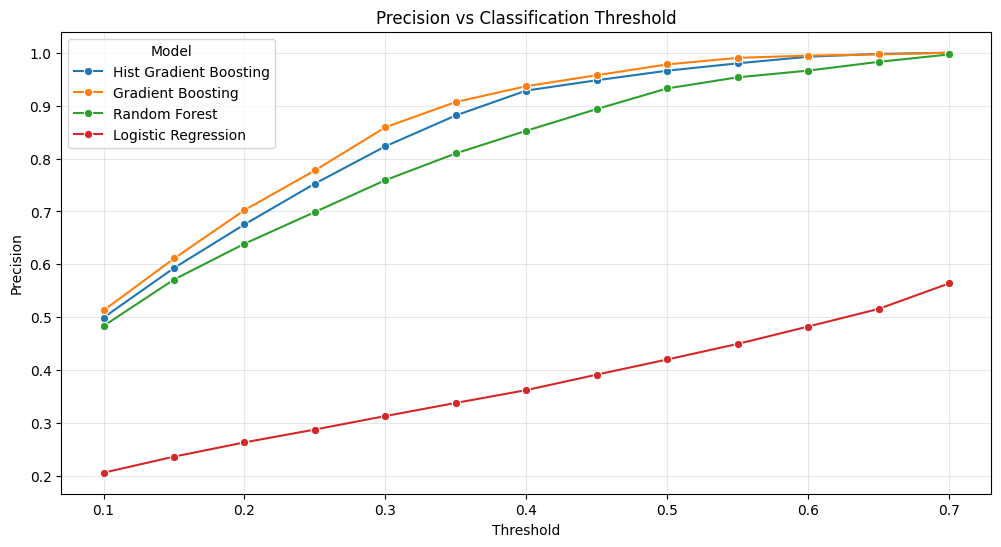

In [33]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=threshold_df,
    x='Threshold',
    y='Precision',
    hue='Model',
    marker='o'
)

plt.title('Precision vs Classification Threshold')
plt.grid(alpha=0.3)
plt.show()

Train final gradient boosting model

In [34]:
from sklearn.base import clone

final_model = clone(
    validation_models['Gradient Boosting']
)

final_model.fit(X_train, y_train)

print("Final Gradient Boosting model trained.")

Final Gradient Boosting model trained.


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

FINAL_THRESHOLD = 0.30

y_prob = final_model.predict_proba(X_test)[:, 1]

y_pred = (
    y_prob >= FINAL_THRESHOLD
).astype(int)

print("Final Model: Gradient Boosting")
print("Threshold:", FINAL_THRESHOLD)

print("\nAccuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Precision:",
      round(precision_score(y_test, y_pred), 4))

print("Recall:",
      round(recall_score(y_test, y_pred), 4))

print("F1 Score:",
      round(f1_score(y_test, y_pred), 4))

print("ROC AUC:",
      round(roc_auc_score(y_test, y_prob), 4))

print("PR AUC:",
      round(average_precision_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Final Model: Gradient Boosting
Threshold: 0.3

Accuracy: 0.9669
Precision: 0.862
Recall: 0.7441
F1 Score: 0.7987
ROC AUC: 0.9774
PR AUC: 0.8841

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98     17534
           1       0.86      0.74      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.92      0.87      0.89     19230
weighted avg       0.97      0.97      0.97     19230



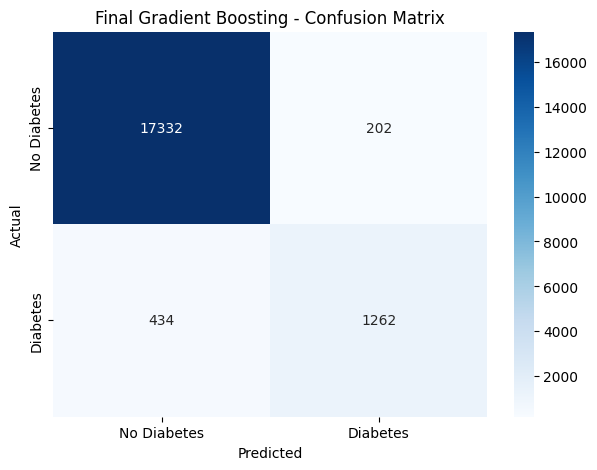

In [36]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Final Gradient Boosting - Confusion Matrix')

plt.show()

In [37]:
print(final_model)
print("\nPipeline steps:")
print(final_model.named_steps)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'HbA1c_level',
                                                   'blood_glucose_level',
                                                   'hypertension',
                                                   'heart_disease']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['gender',
                                                   'smoking_history'])])),
                ('classifier', GradientBoostingClassifier(random_state=42))])

Pipeline steps:
{'preprocessor': ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['age', 'bmi', 'HbA1c_level',


In [38]:
preprocessor = final_model[:-1]
tree_model = final_model.steps[-1][1]

print("Model:", tree_model)

Model: GradientBoostingClassifier(random_state=42)


In [39]:
X_shap = X_test.sample(1000, random_state=42)
X_shap_transformed = preprocessor.transform(X_shap)
feature_names = preprocessor.get_feature_names_out()

print("Transformed shape:", X_shap_transformed.shape)
print("Number of features:", len(feature_names))

Transformed shape: (1000, 15)
Number of features: 15


In [40]:
!pip install shap -q

In [41]:
import shap
import pandas as pd

explainer = shap.TreeExplainer(tree_model)

shap_values = explainer.shap_values(
    X_shap_transformed
)

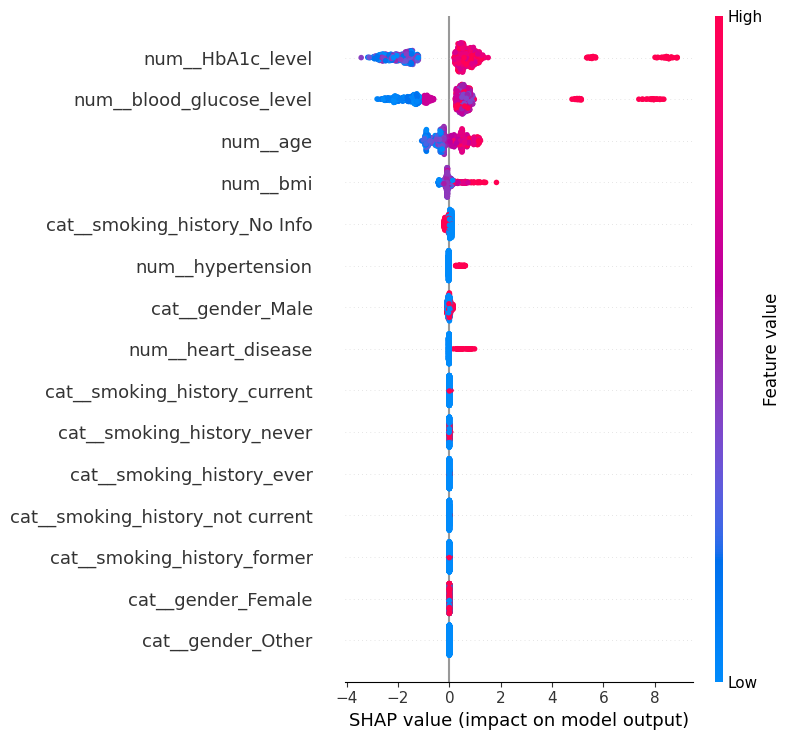

In [42]:
X_shap_df = pd.DataFrame(
    X_shap_transformed,
    columns=feature_names
)

shap.summary_plot(
    shap_values,
    X_shap_df,
    show=True
)

In [43]:
import numpy as np
import pandas as pd

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Mean Absolute SHAP': np.abs(shap_values).mean(axis=0)
})

importance_df = importance_df.sort_values(
    by='Mean Absolute SHAP',
    ascending=False
)

print(importance_df.round(5))

                             Feature  Mean Absolute SHAP
2                   num__HbA1c_level             1.47754
3           num__blood_glucose_level             1.12965
0                           num__age             0.48323
1                           num__bmi             0.18236
9       cat__smoking_history_No Info             0.05898
4                  num__hypertension             0.05761
7                   cat__gender_Male             0.03920
5                 num__heart_disease             0.03830
10      cat__smoking_history_current             0.00128
13        cat__smoking_history_never             0.00078
11         cat__smoking_history_ever             0.00058
14  cat__smoking_history_not current             0.00045
12       cat__smoking_history_former             0.00001
6                 cat__gender_Female             0.00000
8                  cat__gender_Other             0.00000


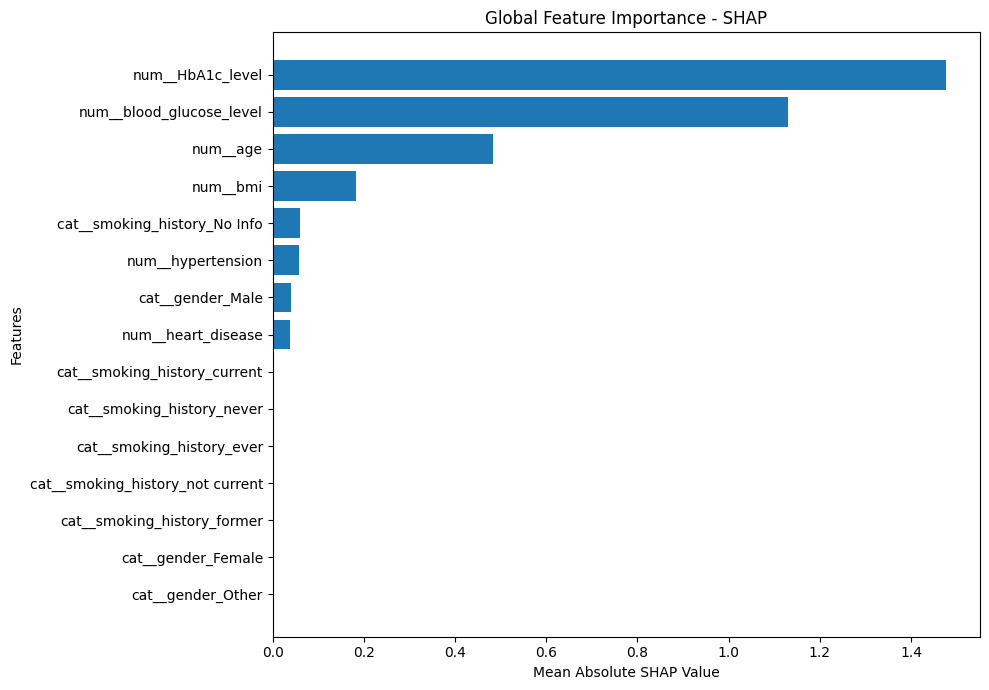

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.barh(
    importance_df['Feature'][::-1],
    importance_df['Mean Absolute SHAP'][::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Features")
plt.title("Global Feature Importance - SHAP")

plt.tight_layout()
plt.show()

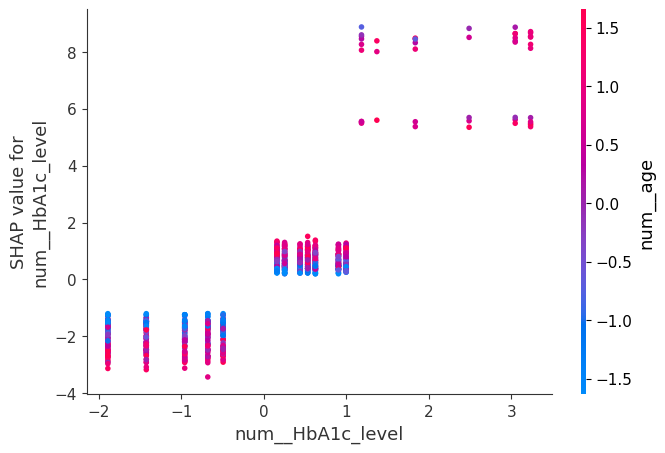

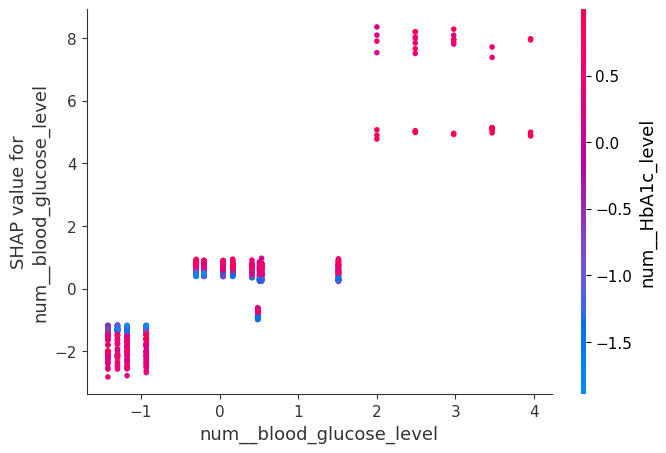

In [45]:
shap.dependence_plot(
    2,
    shap_values,
    X_shap_transformed,
    feature_names=feature_names
)

shap.dependence_plot(
    3,
    shap_values,
    X_shap_transformed,
    feature_names=feature_names
)

plt.show()

### SHAP-Based Model Interpretability

SHAP analysis was performed to understand how individual features influence the predictions of the final Gradient Boosting classifier.

The analysis identified **HbA1c level, blood glucose level, age, and BMI** as the four most influential features.

The mean absolute SHAP values showed that HbA1c level (1.47754) had the highest contribution, followed by blood glucose level (1.12965), age (0.48323), and BMI (0.18236).

The SHAP summary and dependence plots further demonstrated that higher HbA1c and blood glucose values generally contribute positively towards the model's diabetes prediction, whereas lower values tend to contribute negatively.

These findings indicate that the model relies primarily on important glycemic indicators, while demographic and lifestyle-related variables provide additional predictive information.

Overall, SHAP improved the interpretability of the model by explaining both global feature importance and individual feature contributions. However, these explanations represent learned predictive associations rather than causal or clinical conclusions.

In [46]:
# Create an error analysis dataframe

error_analysis = X_test.copy()

error_analysis["Actual"] = y_test
error_analysis["Predicted"] = y_pred

# Identify incorrect predictions

false_negatives = error_analysis[
    (error_analysis["Actual"] == 1) &
    (error_analysis["Predicted"] == 0)
]

false_positives = error_analysis[
    (error_analysis["Actual"] == 0) &
    (error_analysis["Predicted"] == 1)
]

print("False Negatives:", len(false_negatives))
print("False Positives:", len(false_positives))

print("\nFalse Negative Feature Statistics:")
print(false_negatives.describe())

print("\nFalse Positive Feature Statistics:")
print(false_positives.describe())

False Negatives: 434
False Positives: 202

False Negative Feature Statistics:
              age  hypertension  heart_disease         bmi  HbA1c_level  \
count  434.000000    434.000000     434.000000  434.000000   434.000000   
mean    58.605991      0.149770       0.071429   30.251728     6.127419   
std     15.496377      0.357257       0.257837    6.584554     0.304712   
min     14.000000      0.000000       0.000000   13.730000     5.700000   
25%     48.000000      0.000000       0.000000   27.320000     5.800000   
50%     59.500000      0.000000       0.000000   27.800000     6.100000   
75%     72.000000      0.000000       0.000000   33.060000     6.500000   
max     80.000000      1.000000       1.000000   66.880000     6.600000   

       blood_glucose_level  Actual  Predicted  
count           434.000000   434.0      434.0  
mean            149.163594     1.0        0.0  
std              18.669323     0.0        0.0  
min             126.000000     1.0        0.0  
25%   

In [47]:
actual_diabetic = X_test[y_test == 1]

print("Actual Diabetic Patients:")
print(actual_diabetic.describe())

print("\nMissed Diabetic Patients:")
print(false_negatives.describe())

Actual Diabetic Patients:
               age  hypertension  heart_disease          bmi  HbA1c_level  \
count  1696.000000   1696.000000    1696.000000  1696.000000  1696.000000   
mean     60.548349      0.231132       0.139151    32.186739     6.962618   
std      14.749832      0.421681       0.346206     7.801741     1.088836   
min       4.000000      0.000000       0.000000    10.980000     5.700000   
25%      52.000000      0.000000       0.000000    27.320000     6.100000   
50%      62.000000      0.000000       0.000000    30.090000     6.600000   
75%      72.000000      0.000000       0.000000    36.335000     7.500000   
max      80.000000      1.000000       1.000000    83.740000     9.000000   

       blood_glucose_level  
count          1696.000000  
mean            195.218160  
std              59.338603  
min             126.000000  
25%             145.000000  
50%             160.000000  
75%             260.000000  
max             300.000000  

Missed Diabetic Pa

In [48]:
import pandas as pd
from sklearn.metrics import recall_score

age_analysis = X_test.copy()

age_analysis["Actual"] = y_test
age_analysis["Predicted"] = y_pred

age_analysis["Age Group"] = pd.cut(
    age_analysis["age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=["18-25", "26-35", "36-45",
            "46-55", "56-65", "65+"]
)

age_recall = age_analysis.groupby(
    "Age Group", observed=False
).apply(
    lambda group: recall_score(
        group["Actual"],
        group["Predicted"],
        zero_division=0
    )
)

print("Recall by Age Group:")
print(age_recall)

Recall by Age Group:
Age Group
18-25    0.794872
26-35    0.558824
36-45    0.648276
46-55    0.712903
56-65    0.779043
65+      0.771223
dtype: float64


/tmp/ipykernel_16/3082916427.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ).apply(


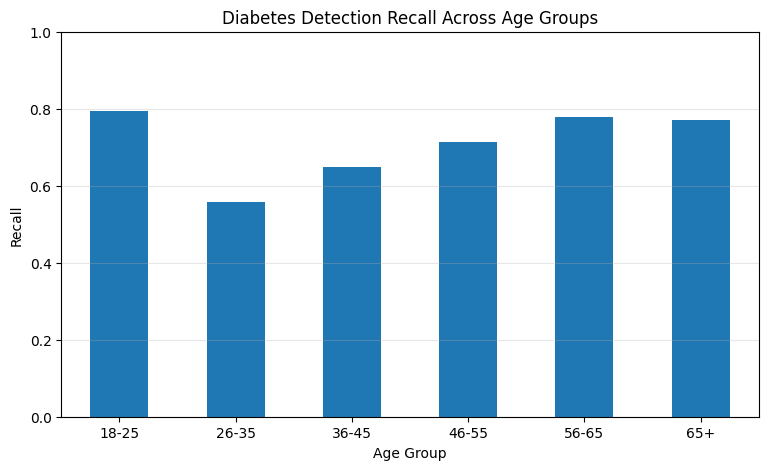

In [49]:
import matplotlib.pyplot as plt

age_recall.plot(
    kind="bar",
    figsize=(9, 5),
    title="Diabetes Detection Recall Across Age Groups"
)

plt.ylabel("Recall")
plt.xlabel("Age Group")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Combine test data and predictions
analysis_df = X_test.copy()

analysis_df["Actual"] = y_test
analysis_df["Predicted"] = y_pred

# Evaluate each subgroup
def evaluate_group(group):
    return pd.Series({
        "Total Patients": len(group),
        "Diabetic Patients": (group["Actual"] == 1).sum(),
        "Accuracy": accuracy_score(
            group["Actual"], group["Predicted"]
        ),
        "Precision": precision_score(
            group["Actual"], group["Predicted"],
            zero_division=0
        ),
        "Recall": recall_score(
            group["Actual"], group["Predicted"],
            zero_division=0
        ),
        "F1 Score": f1_score(
            group["Actual"], group["Predicted"],
            zero_division=0
        )
    })

# Gender-wise evaluation
gender_results = analysis_df.groupby(
    "gender"
).apply(evaluate_group)

print("GENDER-WISE PERFORMANCE")
print(gender_results.round(4))

GENDER-WISE PERFORMANCE
        Total Patients  Diabetic Patients  Accuracy  Precision  Recall  \
gender                                                                   
Female         11344.0              929.0    0.9710     0.8836  0.7438   
Male            7882.0              767.0    0.9611     0.8372  0.7445   
Other              4.0                0.0    1.0000     0.0000  0.0000   

        F1 Score  
gender            
Female    0.8077  
Male      0.7881  
Other     0.0000  


/tmp/ipykernel_16/2156435090.py:39: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ).apply(evaluate_group)


Brier Score: 0.0232


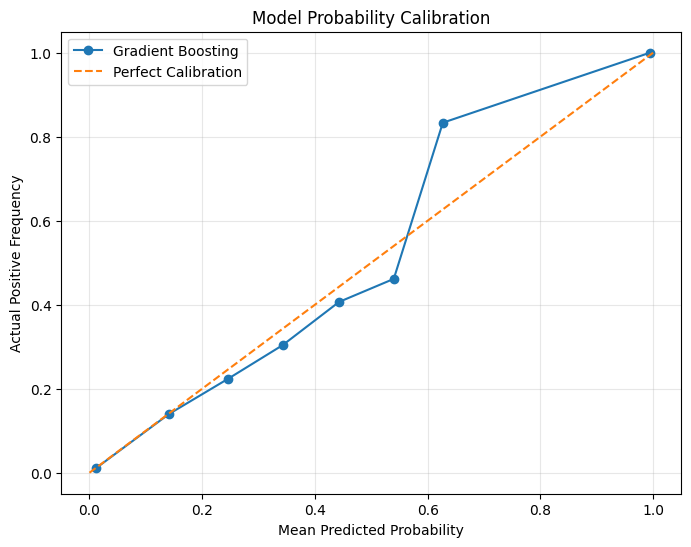

In [51]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

# Get predicted probabilities
y_prob = final_model.predict_proba(X_test)[:, 1]

# Brier score
brier = brier_score_loss(y_test, y_prob)

print("Brier Score:", round(brier, 4))

# Calibration curve
prob_true, prob_pred = calibration_curve(
    y_test,
    y_prob,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Gradient Boosting"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Actual Positive Frequency")
plt.title("Model Probability Calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [52]:

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Use existing predicted probabilities
thresholds = np.arange(0.10, 0.61, 0.05)

results = []

for threshold in thresholds:

    predictions = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Specificity": tn / (tn + fp),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "False Negatives": fn,
        "False Positives": fp
    })

threshold_df = pd.DataFrame(results)

print(threshold_df.round(4).to_string(index=False))


 Threshold  Accuracy  Precision  Recall  Specificity  F1 Score  False Negatives  False Positives
      0.10    0.9106     0.4961  0.9009       0.9115    0.6399              168             1552
      0.15    0.9392     0.6118  0.8485       0.9479    0.7110              257              913
      0.20    0.9531     0.7046  0.8072       0.9673    0.7524              327              574
      0.25    0.9618     0.7858  0.7789       0.9795    0.7824              375              360
      0.30    0.9669     0.8620  0.7441       0.9885    0.7987              434              202
      0.35    0.9696     0.9137  0.7241       0.9934    0.8079              468              116
      0.40    0.9708     0.9458  0.7099       0.9961    0.8110              492               69
      0.45    0.9715     0.9712  0.6969       0.9980    0.8115              514               35
      0.50    0.9717     0.9873  0.6881       0.9991    0.8110              529               15
      0.55    0.9720     0.995

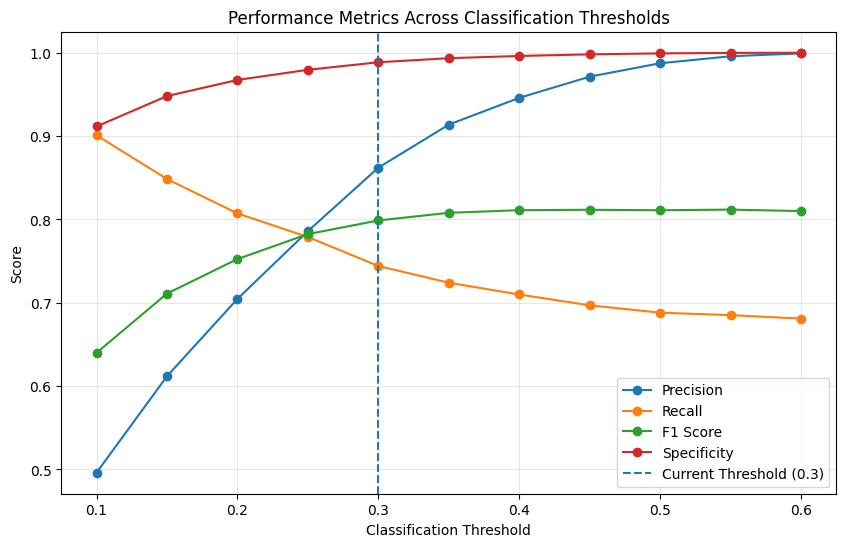

In [53]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Specificity"],
    marker="o",
    label="Specificity"
)

plt.axvline(
    x=0.3,
    linestyle="--",
    label="Current Threshold (0.3)"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Performance Metrics Across Classification Thresholds")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [54]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    accuracy_score
)
import pandas as pd
import numpy as np

# First split: 85% development, 15% final test
X_dev, X_final_test, y_dev, y_final_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Second split: 70% training, 15% validation overall
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.17647,
    random_state=42,
    stratify=y_dev
)

print("Training:", X_train_new.shape)
print("Validation:", X_val.shape)
print("Final Test:", X_final_test.shape)

# Train the existing selected pipeline
final_model.fit(X_train_new, y_train_new)

# Validation probabilities
val_prob = final_model.predict_proba(X_val)[:, 1]

# Evaluate thresholds
threshold_results = []

for threshold in np.arange(0.10, 0.61, 0.01):

    val_pred = (val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, val_pred, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "Specificity": tn / (tn + fp),
        "False Negatives": fn,
        "False Positives": fp
    })

validation_df = pd.DataFrame(threshold_results)

# Example screening objective:
# Find thresholds achieving at least 80% recall
eligible = validation_df[
    validation_df["Recall"] >= 0.80
]

if not eligible.empty:
    best_row = eligible.sort_values(
        "Precision", ascending=False
    ).iloc[0]

    selected_threshold = best_row["Threshold"]

    print("\nSelected Validation Threshold:")
    print(best_row)
else:
    selected_threshold = None
    print("No threshold achieved the recall target.")


Training: (67302, 8)
Validation: (14422, 8)
Final Test: (14422, 8)

Selected Validation Threshold:
Threshold            0.210000
Precision            0.724454
Recall               0.808176
F1 Score             0.764028
Specificity          0.970266
False Negatives    244.000000
False Positives    391.000000
Name: 11, dtype: float64


In [55]:

if selected_threshold is not None:

    test_prob = final_model.predict_proba(
        X_final_test
    )[:, 1]

    final_predictions = (
        test_prob >= selected_threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_final_test,
        final_predictions,
        labels=[0, 1]
    ).ravel()

    print("FINAL MODEL PERFORMANCE")
    print("-----------------------")
    print("Threshold:", selected_threshold)

    print("Accuracy:",
          round(accuracy_score(
              y_final_test, final_predictions
          ), 4))

    print("Precision:",
          round(precision_score(
              y_final_test, final_predictions
          ), 4))

    print("Recall:",
          round(recall_score(
              y_final_test, final_predictions
          ), 4))

    print("F1 Score:",
          round(f1_score(
              y_final_test, final_predictions
          ), 4))

    print("Specificity:",
          round(tn / (tn + fp), 4))

    print("True Positives:", tp)
    print("True Negatives:", tn)
    print("False Positives:", fp)
    print("False Negatives:", fn)


FINAL MODEL PERFORMANCE
-----------------------
Threshold: 0.21
Accuracy: 0.9555
Precision: 0.7276
Recall: 0.7917
F1 Score: 0.7583
Specificity: 0.9713
True Positives: 1007
True Negatives: 12773
False Positives: 377
False Negatives: 265


Dumping the models

In [56]:

import joblib
import os

# Create model directory
os.makedirs("/kaggle/working/models", exist_ok=True)

# Save model and configuration together
model_artifact = {
    "model": final_model,
    "threshold": selected_threshold,
    "model_name": "Gradient Boosting",
    "features": list(X.columns)
}

joblib.dump(
    model_artifact,
    "/kaggle/working/models/diabetes_model.pkl"
)

print("Model saved successfully!")
print("Threshold:", selected_threshold)
print("Features:", list(X.columns))


Model saved successfully!
Threshold: 0.21
Features: ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level']
